# Question 1: how far has price-to-income moved in each metro since 2015?

**Price-to-income** is Zillow's typical home value (ZHVI) divided by ACS 5-year median household income: the number of
years of median income a typical home costs. Source: `gold.mart_metro_month`. The start is the 2015 average; the end is
the latest 12 months, so both sides cover a full year.

Caveats: ACS 5-year income averages five survey years, so it trails current incomes by about two years; months after
2024 reuse the 2020–2024 vintage (`income_is_carried_forward`), which overstates the latest ratio a little while incomes
rise. The 2015 ratio uses the 2011–2015 vintage, published in December 2016. A ratio of two dollar amounts needs no
inflation adjustment.

In [1]:
import common as c
from matplotlib.ticker import FuncFormatter

In [2]:
d = c.price_to_income_change(2015)
d[["start_p2i", "latest_p2i", "change"]]

,start_p2i,latest_p2i,change
metro,,,
Seattle,4.908,6.346,1.439
Nashville,3.878,5.271,1.394
Tampa,3.484,4.810,1.326
Charlotte,3.307,4.612,1.304
Orlando,3.821,4.915,1.094
Atlanta,3.159,4.219,1.060
Phoenix,4.010,5.037,1.026
Dallas-Fort Worth,3.104,4.007,0.903
Raleigh,3.577,4.316,0.739


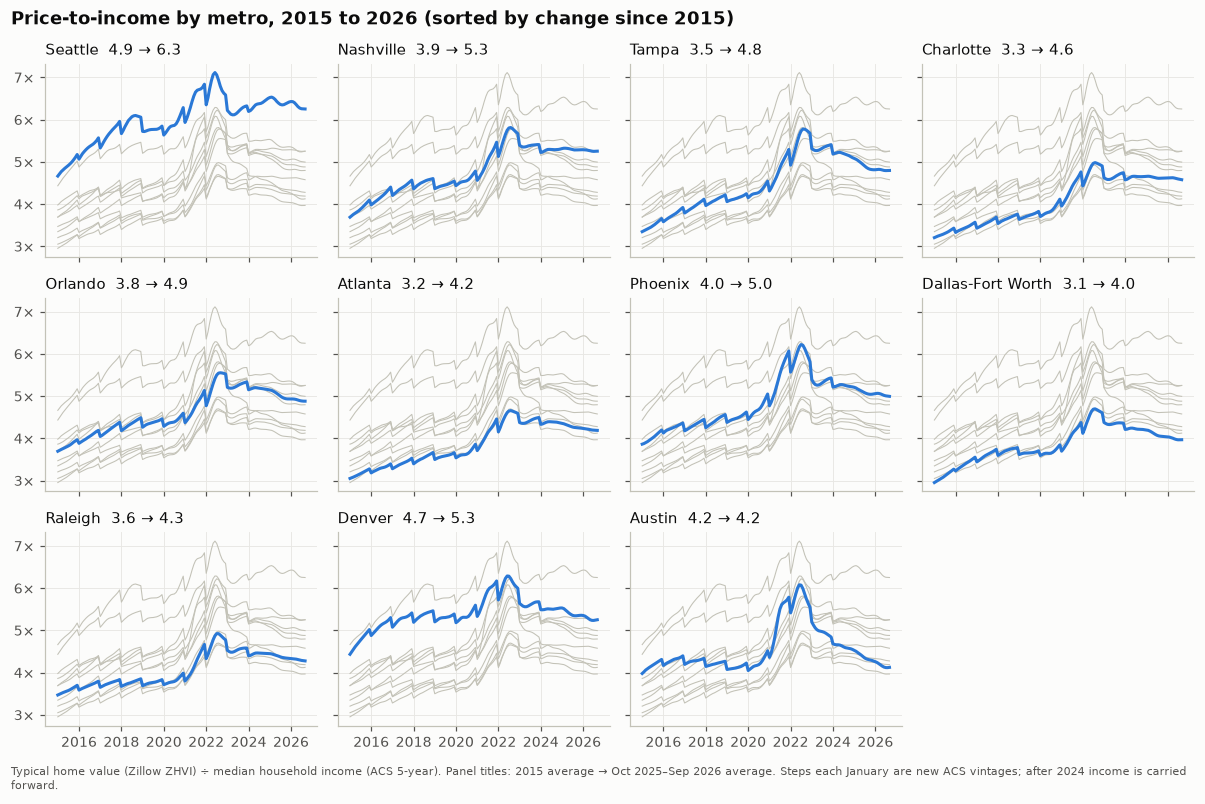

In [3]:
wide = c.q(
    "select month, cbsa_code, price_to_income from gold.mart_metro_month where price_to_income is not null"
).pivot(index="month", columns="cbsa_code", values="price_to_income")
wide.columns = wide.columns.map(c.METRO)
titles = {m: f"{m}  {r.start_p2i:.1f} → {r.latest_p2i:.1f}" for m, r in d.iterrows()}
fig = c.small_multiples(wide, d.index, titles, FuncFormatter(lambda v, _: f"{v:.0f}×"))
c.save(
    fig,
    "q1_price_to_income_trend",
    "Price-to-income by metro, 2015 to 2026 (sorted by change since 2015)",
    "Typical home value (Zillow ZHVI) ÷ median household income (ACS 5-year). Panel titles: 2015 average → "
    f"{c.LATEST_12M} average. Steps each January are new ACS vintages; after 2024 income is carried forward.",
)

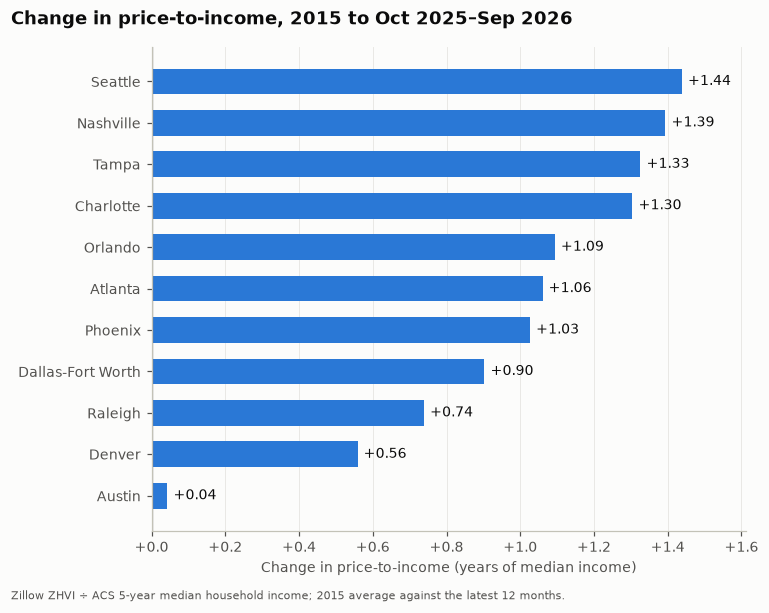

In [4]:
fig, ax = c.ranked_bars(d.change, "{:+.2f}", FuncFormatter(lambda v, _: f"{v:+.1f}"))
ax.set_xlabel("Change in price-to-income (years of median income)")
c.save(
    fig,
    "q1_price_to_income_change",
    f"Change in price-to-income, 2015 to {c.LATEST_12M}",
    "Zillow ZHVI ÷ ACS 5-year median household income; 2015 average against the latest 12 months.",
)

## Answer

In [5]:
top, low = d.iloc[0], d.iloc[-1]
print(
    f"Price-to-income rose in {(d.change > 0).sum()} of {len(d)} metros from 2015 to {c.LATEST_12M}; "
    f"{d.index[0]} rose most ({top.start_p2i:.1f} to {top.latest_p2i:.1f}, {top.change:+.2f} years of income) "
    f"and {d.index[-1]} least ({low.start_p2i:.1f} to {low.latest_p2i:.1f}, {low.change:+.2f})."
)

Price-to-income rose in 11 of 11 metros from 2015 to Oct 2025–Sep 2026; Seattle rose most (4.9 to 6.3, +1.44 years of income) and Austin least (4.2 to 4.2, +0.04).
